# Practical 3C — Energy Consumption LSTM Autoencoder

Extracted from `3C.pdf`. Original displayed outputs omitted; executable Python code retained.

**Required local inputs:** `energy consumption.csv`

            Timestamp  Electricity_Consumed  Temperature  Humidity  \
0 2024-01-01 00:00:00              0.457786     0.469524  0.396368   
1 2024-01-01 00:30:00              0.351956     0.465545  0.451184   
2 2024-01-01 01:00:00              0.482948     0.285415  0.408289   
3 2024-01-01 01:30:00              0.628838     0.482095  0.512308   
4 2024-01-01 02:00:00              0.335974     0.624741  0.672021   

   Wind_Speed  Avg_Past_Consumption  Anomaly_Label  
0    0.445441              0.692057              0  
1    0.458729              0.539874              0  
2    0.470360              0.614724              0  
3    0.576241              0.757044              0  
4    0.373004              0.673981              0  


C:\Users\Shubham\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                          │ (None, 32)                  │           4,864 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ repeat_vector (RepeatVector)         │ (None, 12, 32)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_1 (LSTM)                        │ (None, 12, 32)              │           8,320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ time_distributed (TimeDistributed)   │ (None, 12, 5)               │             165 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 13,349 (52.14 KB)

 Trainable params: 13,349 (52.14 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
107/107 ━━━━━━━━━━━━━━━━━━━━ 36s 92ms/step - loss: 0.0658 - val_loss: 0.0255
Epoch 2/10
107/107 ━━━━━━━━━━━━━━━━━━━━ 4s 35ms/step - loss: 0.0228 - val_loss: 0.0214
Epoch 3/10
107/107 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - loss: 0.0211 - val_loss: 0.0203
Epoch 4/10
107/107 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step - loss: 0.0201 - val_loss: 0.0197
Epoch 5/10
107/107 ━━━━━━━━━━━━━━━━━━━━ 5s 30ms/step - loss: 0.0195 - val_loss: 0.0194
Epoch 6/10
107/107 ━━━━━━━━━━━━━━━━━━━━ 6s 38ms/step - loss: 0.0192 - val_loss: 0.0191
Epoch 7/10
107/107 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - loss: 0.0190 - val_loss: 0.0189
Epoch 8/10
107/107 ━━━━━━━━━━━━━━━━━━━━ 4s 37ms/step - loss: 0.0188 - val_loss: 0.0186
Epoch 9/10
107/107 ━━━━━━━━━━━━━━━━━━━━ 4s 34ms/step - loss: 0.0186 - val_loss: 0.0185
Epoch 10/10
107/107 ━━━━━━━━━━━━━━━━━━━━ 6s 40ms/step - loss: 0.0185 - val_loss: 0.0184
Anomaly Threshold: 0.02505365902326074

Confusion Matrix:
[[646  15]
 [281  47]]

Classification Report:
              precision

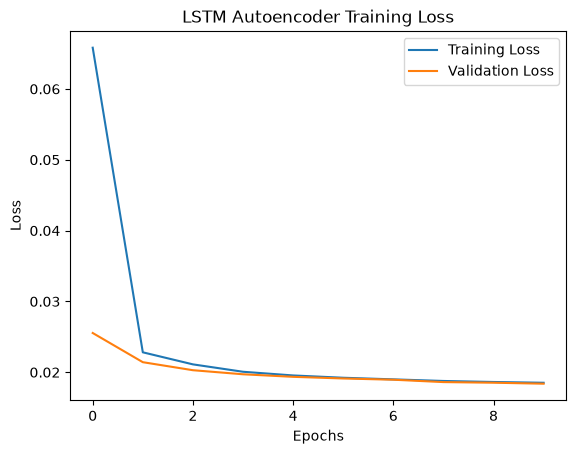

Total Test Windows: 989
Actual Anomalies: 328
Detected Anomalies: 62

Anomaly Detection Completed!


In [1]:
# 1. Import necessary packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, RepeatVector, TimeDistributed, Dense
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import classification_report, confusion_matrix
# 2. Load the dataset
data = pd.read_csv('LP_IV_Updated Datasets/LP_IV_Updated Datasets/AutoEncoder/Energy Consumption/energy consumption.csv')
# Sort data according to timestamp
data['Timestamp'] = pd.to_datetime(data['Timestamp'], dayfirst=True)
data = data.sort_values('Timestamp')
print(data.head())
# 3. Preprocess the data
features = [
    'Electricity_Consumed',
    'Temperature',
    'Humidity',
    'Wind_Speed',
    'Avg_Past_Consumption'
]
# Fill missing values
data[features] = data[features].fillna(data[features].median())
# Separate features and labels
X = data[features].values
y = data['Anomaly_Label'].values
# Split data chronologically (80% training, 20% testing)
split = int(len(X) * 0.8)
X_train = X[:split]
X_test = X[split:]
y_train = y[:split]
y_test = y[split:]
# 4. Select only normal data for training
X_normal = X_train[y_train == 0]
# Normalize the data
scaler = MinMaxScaler()
X_normal = scaler.fit_transform(X_normal)
X_test = scaler.transform(X_test)
# 5. Create time windows
window_size = 12
def create_windows(data):
    windows = []
    for i in range(len(data) - window_size + 1):
        windows.append(data[i:i + window_size])
    return np.array(windows)
# Create normal training windows
X_windows = create_windows(X_normal)
# Split into training and validation data
split2 = int(len(X_windows) * 0.9)
X_train_seq = X_windows[:split2]
X_val_seq = X_windows[split2:]
# Create testing windows
X_test_seq = create_windows(X_test)
# Assign label 1 if any anomaly occurs in a window
y_test_seq = np.array([
    max(y_test[i:i + window_size])
    for i in range(len(y_test) - window_size + 1)
])
# 6. Build LSTM Autoencoder
model = Sequential([
    LSTM(32, activation='relu', input_shape=(window_size, 5)),
    RepeatVector(window_size),
    LSTM(32, activation='relu', return_sequences=True),
    TimeDistributed(Dense(5))
])
# 7. Compile the model
model.compile(
    optimizer='adam',
    loss='mse'
)
model.summary()
# 8. Train the model using normal data
history = model.fit(
    X_train_seq,
    X_train_seq,
    epochs=10,
    batch_size=32,
    validation_data=(X_val_seq, X_val_seq)
)
# 9. Calculate reconstruction error
val_pred = model.predict(X_val_seq, verbose=0)
val_error = np.mean(
    np.square(X_val_seq - val_pred),
    axis=(1, 2)
)
# Set anomaly threshold
threshold = np.percentile(val_error, 95)
print("Anomaly Threshold:", threshold)
# 10. Detect anomalies in test data
test_pred = model.predict(X_test_seq, verbose=0)
test_error = np.mean(
    np.square(X_test_seq - test_pred),
    axis=(1, 2)
)
y_pred = (test_error > threshold).astype(int)
# 11. Evaluate the model
print("\nConfusion Matrix:")
print(confusion_matrix(y_test_seq, y_pred))
print("\nClassification Report:")
print(classification_report(y_test_seq, y_pred, zero_division=0))
# 12. Plot training loss
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('LSTM Autoencoder Training Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()
# 13. Display results
print("Total Test Windows:", len(y_test_seq))
print("Actual Anomalies:", np.sum(y_test_seq))
print("Detected Anomalies:", np.sum(y_pred))
print("\nAnomaly Detection Completed!")
